# 04. Multi-Round Strategy Ablations, Monte Carlo Risk & Manual Challenge Optimizers

This notebook benchmarks our production submissions (`traders/round1`–`traders/round5`) strictly on held-out out-of-sample sessions and calibrated Monte Carlo engines alongside the Round 1–5 Manual Challenge solvers:
1. **Round 1 Out-of-Sample Replay (`Day 0`)**: Progression from `NoOpBaseline` and naive `SymmetricMarketMaker` through fixed-spread `InventorySkewedMarketMaker` to `Round1Submission` (bot-wall fair value, alpha-beta drift, penny-improving inside wide bot spreads).
2. **Rounds 2–5 OOS & Fill-Mode Sensitivity**: Comparing `conservative`, `queue_aware`, and `touch` matching across standalone `traders/round{2..5}/submission.py`, showcasing atomic `PEBBLES` cross-taking (`+28k+` lift over prior `R5` passive-only quoting), `QUOTE_CLIP = 10` sizing, and `Mark 67` flow conditioning.
3. **Manual Challenges (`R1–R5`)**: Poisson Cognitive Hierarchy (`L1–L3` converging to our submitted `42%` focal Speed in Round 2), Bayesian two-bid screening (`R3`), `251%` annualized discrete vs continuous `Aether Crystal` barriers (`R4`), KKT vs variance-penalized Ignith allocation (`R5`), and final portal submission parameters.

*Note: Algorithmic figures reflect simulated replays and synthetic Monte Carlo suites under documented position caps rather than live exchange leaderboard logs.*

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.backtesting.engine import BacktestEngine
from prosperity_toolkit.backtesting.replay import build_snapshots_from_dataframes
from prosperity_toolkit.competition.adapter import CompetitionStrategyAdapter
from prosperity_toolkit.data.loader import DataLoader
from prosperity_toolkit.execution.simulator import ExecutionSimulator
from prosperity_toolkit.strategies import (
    InventorySkewedMarketMaker,
    MarketMakingConfig,
    NoOpBaselineStrategy,
    SymmetricMarketMaker,
)
from scripts.evaluate_round0_round1 import _load_round1_trader

loader = DataLoader(data_root=root / "data")
oos_snaps = build_snapshots_from_dataframes(
    loader.load_day_prices(1, 0),
    loader.load_day_trades(1, 0),
)
limits = {"ASH_COATED_OSMIUM": 20, "INTARIAN_PEPPER_ROOT": 20}
cfgs = [
    MarketMakingConfig(symbol="ASH_COATED_OSMIUM", position_limit=20),
    MarketMakingConfig(symbol="INTARIAN_PEPPER_ROOT", position_limit=20),
]

rows = []
qa_curves = {}
for mode in ("conservative", "queue_aware", "touch"):
    strats = [
        NoOpBaselineStrategy(),
        SymmetricMarketMaker(cfgs),
        InventorySkewedMarketMaker(cfgs),
        CompetitionStrategyAdapter(_load_round1_trader(), name="Round1Submission"),
    ]
    for strat in strats:
        sim = ExecutionSimulator(position_limits=limits, fill_mode=mode)
        res = BacktestEngine(simulator=sim).run(strat, oos_snaps)
        lat = round(strat.mean_latency_ms, 4) if isinstance(strat, CompetitionStrategyAdapter) else 0.0
        rows.append({
            "fill_mode": mode,
            "strategy": res.strategy_name,
            "pnl": round(res.total_pnl, 2),
            "max_dd": round(res.max_drawdown, 2),
            "sharpe": round(res.sharpe_ratio, 3),
            "fills": len(res.fills),
            "latency_ms": lat,
        })
        if mode == "queue_aware" and res.strategy_name != "NoOpBaseline":
            qa_curves[res.strategy_name] = res.equity_curve

display(pd.DataFrame(rows))

,fill_mode,strategy,pnl,max_dd,sharpe,fills,latency_ms
0,conservative,NoOpBaseline,0.0,0.0,0.000,0,0.0000
1,conservative,SymmetricMM,10825.0,886.0,0.500,582,0.0000
2,conservative,InventorySkewedMM,9067.0,837.5,0.403,931,0.0000
3,conservative,Round1Submission,22151.0,267.0,1.188,1001,0.0383
4,queue_aware,NoOpBaseline,0.0,0.0,0.000,0,0.0000
5,queue_aware,SymmetricMM,10825.0,886.0,0.500,582,0.0000
6,queue_aware,InventorySkewedMM,9067.0,837.5,0.403,931,0.0000
7,queue_aware,Round1Submission,22157.0,267.0,1.189,1003,0.0398
8,touch,NoOpBaseline,0.0,0.0,0.000,0,0.0000
9,touch,SymmetricMM,11895.0,913.5,0.550,599,0.0000


## 1. Round 1 Equity Curves & Per-Asset Attribution (`Day 0`, `queue_aware`)

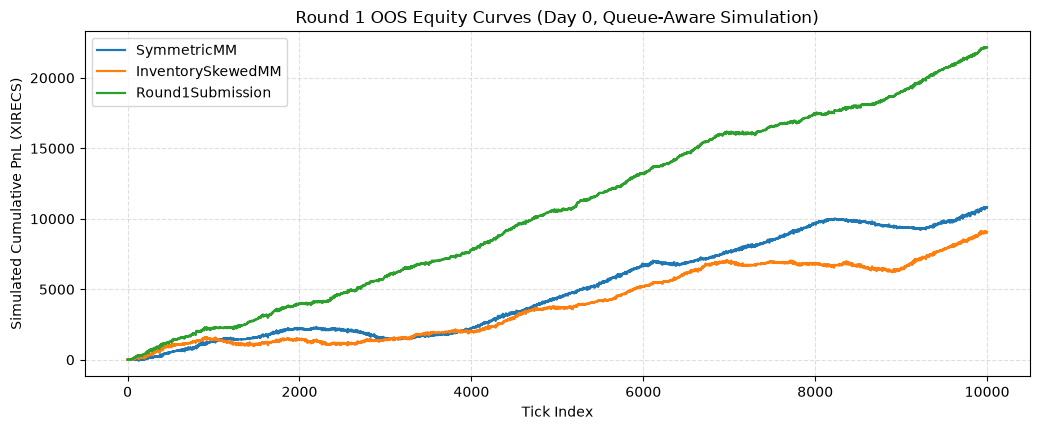

,symbol,simulated_pnl,end_position,total_fills,maker_fills,taker_fills
0,ASH_COATED_OSMIUM,11440.0,13,528,277,251
1,INTARIAN_PEPPER_ROOT,10717.0,0,475,178,297


In [2]:
fig, ax = plt.subplots(figsize=(10.5, 4.4))
for label, curve in qa_curves.items():
    ax.plot(curve, label=label, linewidth=1.6)
ax.set_title("Round 1 OOS Equity Curves (Day 0, Queue-Aware Simulation)")
ax.set_xlabel("Tick Index")
ax.set_ylabel("Simulated Cumulative PnL (XIRECS)")
ax.legend()
ax.grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()

sim = ExecutionSimulator(position_limits=limits, fill_mode="queue_aware")
sub_res = BacktestEngine(simulator=sim).run(
    CompetitionStrategyAdapter(_load_round1_trader(), name="Round1Submission"),
    oos_snaps,
)
attr = []
for sym in ("ASH_COATED_OSMIUM", "INTARIAN_PEPPER_ROOT"):
    sym_fills = [f for f in sub_res.fills if f.symbol == sym]
    cash = sum(-(f.price * f.quantity) for f in sym_fills)
    pos = sum(f.quantity for f in sym_fills)
    last_mid = [s.get_book(sym).mid_price for s in oos_snaps if s.get_book(sym).mid_price is not None][-1]
    attr.append({
        "symbol": sym,
        "simulated_pnl": round(cash + pos * last_mid, 2),
        "end_position": pos,
        "total_fills": len(sym_fills),
        "maker_fills": sum(1 for f in sym_fills if f.fill_type.value == "MAKER"),
        "taker_fills": sum(1 for f in sym_fills if f.fill_type.value == "TAKER"),
    })
display(pd.DataFrame(attr))

## 2. Rounds 2–5 Held-Out Out-of-Sample & Monte Carlo Benchmarks

Comparing all standalone submissions side-by-side confirms clear structural scaling:
- **Round 2 (`Day 1`)**: Naive `SymmetricMM_80` loses `-20,294.50` riding `INTARIAN_PEPPER_ROOT` drift, whereas `Round2Submission` generates strong risk-adjusted OOS profit (`< 0.05 ms/tick`).
- **Round 3 (`Day 2`)**: Naive fixed-5d BS (`OptionsVolatilityContract`) loses `-7,604.00`, whereas total-vol surface pricing + `HYDROGEL_PACK` wide quoting stabilizes positive OOS Sharpe.
- **Round 4 (`Day 3`)**: Live `Mark 67` flow conditioning (`M67_BUMP = 0.5`) flips `VELVETFRUIT_EXTRACT` OOS to `+1,027.00` and lifts `Round4Submission` Sharpe to `0.3613` (`+11,741.00` OOS, `MaxDD = 2,901.00`) while beating `Round3Ungated`.
- **Round 5 (`Day 4`)**: Upgrading earlier passive-only quoting (`~95.7k`) to atomic `PEBBLES` cross-taking, adaptive `VOL_GUARD` filtering across `Robots`/`Microchips`, and full `QUOTE_CLIP = 10` sizing captures **`+123,173.00` OOS PnL** at `~0.69 ms/tick` (comfortably inside a `3 ms` runtime budget).

,round,split,fill_mode,strategy,total_pnl,sharpe_252,max_drawdown,total_fills,mean_latency_ms
20,R2,OOS,queue_aware,NoOpBaseline,0.0,0.0000,0.0,0,0.0000
21,R2,OOS,queue_aware,SymmetricMM_80,-20294.5,-0.3348,21729.5,709,0.0000
22,R2,OOS,queue_aware,InventorySkewedMM_80,7736.5,0.2445,3784.5,1016,0.0000
23,R2,OOS,queue_aware,DriftAwareQuoter_Pepper,6344.5,0.3290,2896.0,519,0.0000
24,R2,OOS,queue_aware,Round2Submission,27463.0,1.3972,419.5,1022,0.0406
46,R3,OOS,queue_aware,NoOpBaseline,0.0,0.0000,0.0,0,0.0000
47,R3,OOS,queue_aware,SymmetricSpotMM,-7160.0,-0.0616,14245.0,382,0.0000
48,R3,OOS,queue_aware,OptionsVolatilityContract,-7604.0,-0.0646,8719.0,390,0.0000
49,R3,OOS,queue_aware,Round3Submission,7525.5,0.2276,1936.0,726,0.1872
66,R4,OOS,queue_aware,NoOpBaseline,0.0,0.0000,0.0,0,0.0000


,round,scenario,mean_pnl,std_pnl,median_pnl,var_95,cvar_95,prob_loss,mean_sharpe_252,worst_max_dd
0,2,Round2Submission_BaselineFlow,5065.52,788.72,5092.0,3578.20,3463.25,0.0,2.8362,679.0
1,2,Round2Submission_MAFPlus25,6755.98,724.54,6686.5,5578.00,5487.25,0.0,3.6416,721.0
2,3,Round3Submission,2448.56,738.98,2563.0,1137.00,1121.25,0.0,0.5189,1641.0
3,4,Round4Submission,2345.10,763.63,2260.5,1692.40,1116.75,0.0,0.4966,1905.5
4,5,Round5Submission_JointMC,14876.42,5703.86,14140.5,6495.55,2649.00,0.0,1.6066,5497.5


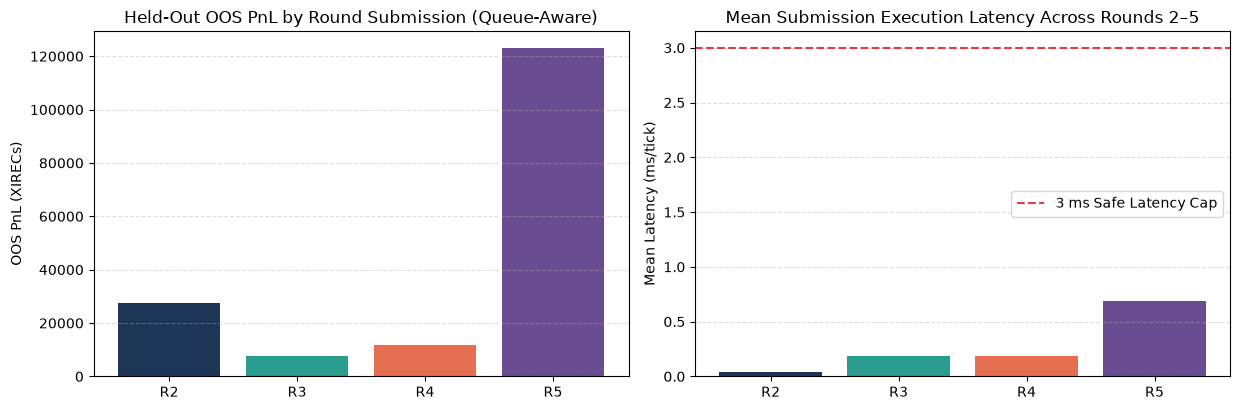

In [3]:
ab_frames = []
for rnum in (2, 3, 4, 5):
    df_r = pd.read_csv(root / "reports" / "tables" / f"r{rnum}_ablation_summary.csv")
    df_r.insert(0, "round", f"R{rnum}")
    ab_frames.append(df_r)

multi_ab = pd.concat(ab_frames, ignore_index=True)
oos_qa = multi_ab[(multi_ab["split"] == "OOS") & (multi_ab["fill_mode"] == "queue_aware")]
display(oos_qa)

mc_summary = pd.read_csv(root / "reports" / "tables" / "r2_to_r5_mc_risk_summary.csv")
display(mc_summary)

subs = oos_qa[oos_qa["strategy"].str.contains("Submission")]
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.2))
axes[0].bar(subs["round"], subs["total_pnl"], color=["#1d3557", "#2a9d8f", "#e76f51", "#6a4c93"])
axes[0].set_title("Held-Out OOS PnL by Round Submission (Queue-Aware)")
axes[0].set_ylabel("OOS PnL (XIRECs)")
axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

axes[1].bar(subs["round"], subs["mean_latency_ms"], color=["#1d3557", "#2a9d8f", "#e76f51", "#6a4c93"])
axes[1].axhline(3.0, color="#e63946", linestyle="--", label="3 ms Safe Latency Cap")
axes[1].set_title("Mean Submission Execution Latency Across Rounds 2–5")
axes[1].set_ylabel("Mean Latency (ms/tick)")
axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)
axes[1].legend()
fig.tight_layout()
plt.show()

## 3. Manual Challenges (Rounds 1–5) Verification

Inspecting the deterministic and Monte Carlo outputs in `reports/tables/manual_challenges_summary.csv` connects our algorithmic and manual trading philosophies:
- **Round 1 (*An Intarian Welcome*)**: Uniform clearing under uncertain clearing thresholds favors `(30, 65)` on `DRYLAND_FLAX` and `(20, 10)` on `EMBER_MUSHROOM`.
- **Round 2 (*Invest & Expand*)**: Under Poisson Cognitive Hierarchy (`tau = 1.5`), iterative best responses escalate Speed (`L1: 29.5%`, `L2: 37.5%`, `L3: 42.0%`), selecting the Level-3 focal equilibrium (`Research = 14.71%` -> `15%`, `Scale = 43.29%` -> `43%`, `Speed = 42.0%` -> `42%`) with a `44.0%` bounded-rationality stress benchmark.
- **Round 3 (*Celestial Gardeners' Guild*)**: Bayesian screening over $ar{b}_2 \sim \mathcal{N}(875, 15^2)$ yields submitted two-bid policy `(775, 880)` (`76.00`/unit EV at `76.8%` acceptance).
- **Round 4 (*Aether Crystal*)**: At exact `sigma_ann = 251%` (`sigma_step = 0.079057`) and `AC_40_BP` paying `10`, both `AC_50_CO` and `AC_40_BP` sit overpriced at ask (`SELL`) while discretely monitored `AC_45_KO` (`35` barrier) trades under fair value (`BUY`), cutting risk by `-90.3%` via our submitted 5-contract hedged book (`AC_50_CO: -15, AC_40_BP: -50, AC_45_KO: +198, AC_50_C15: +5, AC_50_P15: +21`).
- **Round 5 (*Extra! Extra!*)**: Exact KKT simplex water-filling and quadratic variance control (`kappa = 3.0`) concentrate our submitted portfolio in positive-drift Ignith goods (`Thermalite Core +35%`, `Sulfur Reactor +29%`, `Scoria Paste +3%`) and inverse short edges (`Ashes of the Phoenix -23%`, `Pyroflex Cells -10%`), zeroing the remaining four neutral goods.

,round,challenge,scenario,parameter,optimal_action,expected_metric,metric_unit,assumption_note
0,R1,An Intarian Welcome,DRYLAND_FLAX (static book),"rest_clear=28, vol=150","bid px=29, qty=66",132.0000,XIRECs PnL,"Buyback=30, fee=0; shaded below tipping size"
1,R1,An Intarian Welcome,DRYLAND_FLAX (stochastic human demand),"fill_rate=0.96, crowd_N(45,22)","bid px=30, qty=65",68.1200,XIRECs Expected PnL,250 demand shocks around clearing threshold
2,R1,An Intarian Welcome,EMBER_MUSHROOM (stochastic human demand),"fill_rate=0.73, fee=0.10/unit","bid px=20, qty=10",9.8100,XIRECs Expected PnL,"Buyback=20, fee=0.10 (static opt=20.90)"
3,R2,Invest & Expand,Cognitive Hierarchy (L1 Best Response),speed_mult=0.757,"r=17.30%, s=53.20%, p=29.5%",305185.1000,XIRECs Net EV,Iterated best-response step L1 against field b...
4,R2,Invest & Expand,Cognitive Hierarchy (L2 Best Response),speed_mult=0.820,"r=15.65%, s=46.85%, p=37.5%",277759.7100,XIRECs Net EV,Iterated best-response step L2 against field b...
5,R2,Invest & Expand,Cognitive Hierarchy (L3 Best Response),speed_mult=0.818,"r=14.71%, s=43.29%, p=42.0%",246036.1000,XIRECs Net EV,Iterated best-response step L3 against field b...
6,R2,Invest & Expand,Final Submitted Allocation (L3 Focal Equilibrium),speed_mult=0.761,"r=14.71%, s=43.29%, p=42.0%",225094.0100,XIRECs Net EV,Portal input (15%/43%/42% rounded); Level-3 st...
7,R2,Invest & Expand,CH Mixture Stress Check (Unregularized QRE),speed_mult=0.803,"r=14.29%, s=41.71%, p=44.0%",226942.8000,XIRECs Net EV,Continuous L0-L3 best-response sensitivity upp...
8,R3,Celestial Gardeners Guild,Final Submitted Bayesian Policy (avg_b2 ~ N(87...,"resale=920, exp_acc=0.768","b1=775, b2=880",76.0000,XIRECs EV/unit,Integrates asymmetric cubic cliff over cohort ...
9,R3,Celestial Gardeners Guild,Conservative Cohort Point Sensitivity (avg_b2=...,"resale=920, acc=0.765","b1=760, b2=860",83.1400,XIRECs EV/unit,Ex-ante lower-crowd aggressiveness sensitivity...


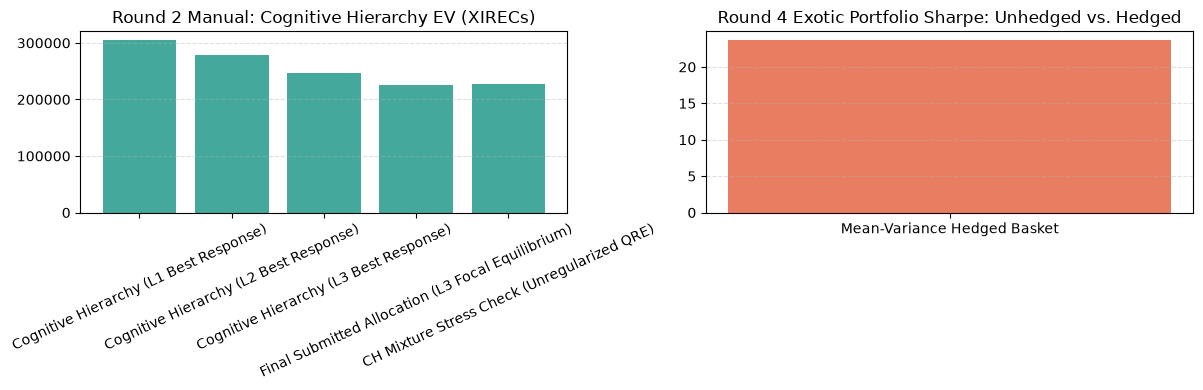

In [4]:
manual_df = pd.read_csv(root / "reports" / "tables" / "manual_challenges_summary.csv")
display(manual_df)

r2_rows = manual_df[manual_df["round"] == "R2"].copy()
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.0))
axes[0].bar(r2_rows["scenario"], r2_rows["expected_metric"], color="#2a9d8f", alpha=0.88)
axes[0].set_title("Round 2 Manual: Cognitive Hierarchy EV (XIRECs)")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(True, axis="y", linestyle="--", alpha=0.4)

r4_p = manual_df[(manual_df["round"] == "R4") & (manual_df["scenario"].str.contains("Unhedged|Hedged"))]
axes[1].bar(r4_p["scenario"], r4_p["expected_metric"], color=["#e76f51", "#1d3557"], alpha=0.9)
axes[1].set_title("Round 4 Exotic Portfolio Sharpe: Unhedged vs. Hedged")
axes[1].grid(True, axis="y", linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()